# 07 - Rework and loops

Which steps do patients repeat, and who comes back? Definitions (clinical steps, repeated lab tests left out):

- **Repeat:** a step occurs more than once in the same case.
- **Immediate repeat:** the same step directly after itself (A, A).
- **Loop back:** a step reappears after a different step in between (A, B, A).
- **Return:** a `Return ER` event, measured from the first discharge.

Lab tests are looked at separately at the end, because repeating blood tests is routine monitoring and not rework.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
sys.path.append(str(ROOT / 'src'))

from conformance import load_log
from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY
from rework import (clinical_steps, rework_per_case, step_rework_table, ward_record_gaps, ward_stay_by_records,
                    return_intervals, lab_tests_per_patient, summarize, RETURN_WINDOWS_DAYS)

apply_style()
log = load_log()
steps = clinical_steps(log)
per_case = rework_per_case(steps)
summary = summarize(log).set_index('metric')['value']
n = len(per_case)
print(f'{n} patients, {len(steps)} clinical events')

995 patients, 6707 clinical events


## 1. Headline numbers

In [2]:
pd.Series({
    'Patients who repeat a clinical step': f"{int(summary['patients_with_rework'])} ({summary['share_with_rework_pct']:.1f}%)",
    'of these, repeat the ward admission record': int(summary['patients_repeating_ward_record']),
    'Extra ward admission records': int(summary['extra_ward_records']),
    'Immediate repeats (A, A)': int(summary['immediate_repeats']),
    'Patients with a loop back (A, B, A)': int(summary['patients_with_loop_back']),
}, name='value').to_frame()

,value
Patients who repeat a clinical step,300 (30.2%)
"of these, repeat the ward admission record",294
Extra ward admission records,356
"Immediate repeats (A, A)",325
"Patients with a loop back (A, B, A)",38


## 2. Which steps are repeated?

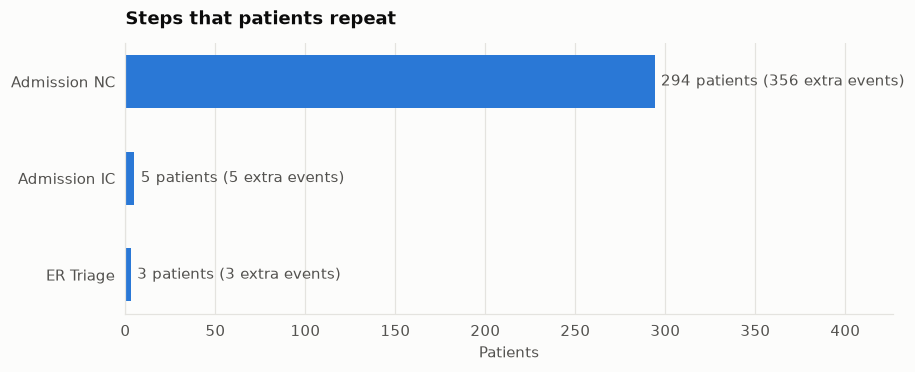

,step,patients,extra_events,share_of_patients_pct
0,Admission NC,294,356,29.5
1,Admission IC,5,5,0.5
2,ER Triage,3,3,0.3


In [3]:
repeated = step_rework_table(steps).sort_values('patients')

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(repeated['step'], repeated['patients'], color=BLUE, height=0.55)
ax.grid(axis='y', visible=False)
for i, (p, e) in enumerate(zip(repeated['patients'], repeated['extra_events'])):
    ax.text(p + repeated['patients'].max() * 0.012, i, f'{p} patients ({e} extra events)', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, repeated['patients'].max() * 1.45)
ax.set_title('Steps that patients repeat')
ax.set_xlabel('Patients')
save_fig(fig, 'rework_steps')
plt.show()
repeated.sort_values('patients', ascending=False).round(1)

## 3. How far apart are the repeated ward records?
Time between consecutive `Admission NC` records of the same patient.

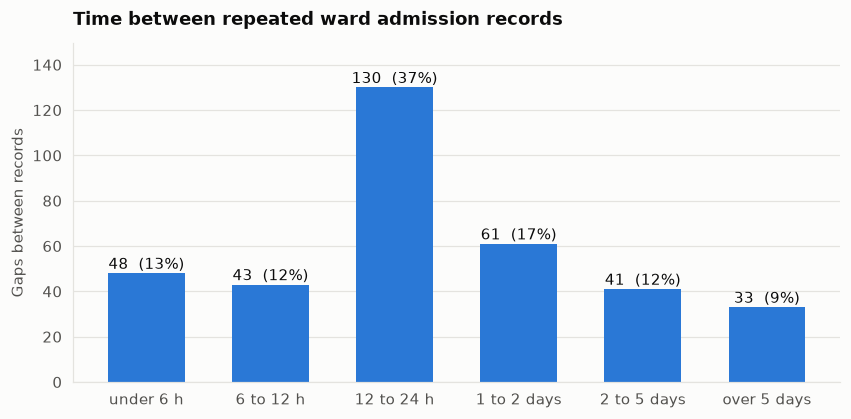

,value
Gaps measured,356.0
Median gap (hours),18.8
Under one day (%),62.1


In [4]:
gaps = ward_record_gaps(steps)
edges = [0, 6, 12, 24, 48, 120, np.inf]
labels = ['under 6 h', '6 to 12 h', '12 to 24 h', '1 to 2 days', '2 to 5 days', 'over 5 days']
buckets = pd.cut(gaps, bins=edges, labels=labels, right=False).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(buckets.index, buckets.values, color=BLUE, width=0.62)
ax.grid(axis='x', visible=False)
for i, v in enumerate(buckets.values):
    ax.text(i, v + buckets.max() * 0.015, f'{v}  ({v / len(gaps) * 100:.0f}%)', ha='center', color=INK, fontsize=10)
ax.set_ylim(0, buckets.max() * 1.15)
ax.set_title('Time between repeated ward admission records')
ax.set_ylabel('Gaps between records')
save_fig(fig, 'rework_ward_gaps')
plt.show()
pd.Series({'Gaps measured': len(gaps), 'Median gap (hours)': round(gaps.median(), 1), 'Under one day (%)': round((gaps < 24).mean() * 100, 1)}, name='value').to_frame()

## 4. Do repeated ward records go with longer stays?
Median days from the first ward record to discharge, by number of ward records.

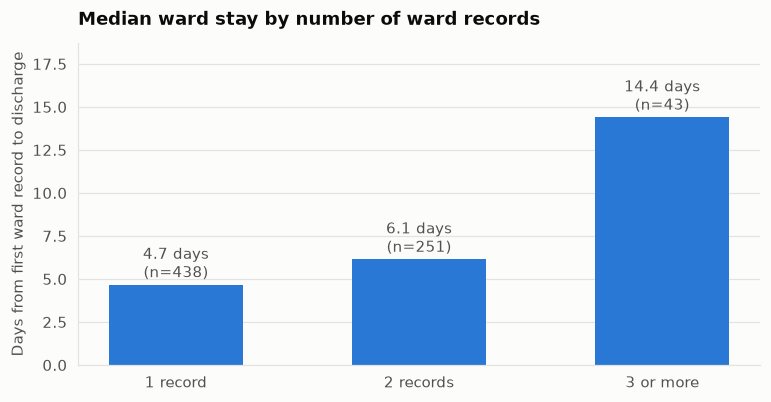

,median,size
group,,
1 record,4.7,438
2 records,6.1,251
3 or more,14.4,43


In [5]:
stays = ward_stay_by_records(log, steps)
stays['group'] = stays['records'].clip(upper=3).map({1: '1 record', 2: '2 records', 3: '3 or more'})
by_group = stays.groupby('group')['stay_days'].agg(['median', 'size']).reindex(['1 record', '2 records', '3 or more'])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_group.index, by_group['median'], color=BLUE, width=0.55)
ax.grid(axis='x', visible=False)
for i, (m, s) in enumerate(zip(by_group['median'], by_group['size'])):
    ax.text(i, m + 0.15, f'{m:.1f} days\n(n={s})', ha='center', va='bottom', color=INK_SECONDARY, fontsize=10)
ax.set_ylim(0, by_group['median'].max() * 1.3)
ax.set_title('Median ward stay by number of ward records')
ax.set_ylabel('Days from first ward record to discharge')
save_fig(fig, 'rework_ward_stay')
plt.show()
by_group.round(1)

## 5. Returns to the ER
Time from the first discharge to the first return. The curve shows the share of all returns that have happened by each day.

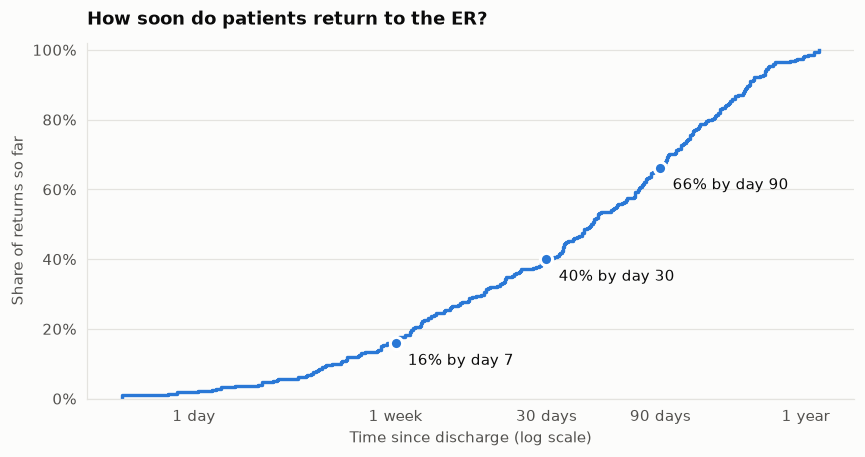

,returns,% of all returns,% of discharged patients
within 7 days,44,15.8,6.0
within 30 days,111,39.9,15.0
within 90 days,184,66.2,24.9


In [6]:
ret = return_intervals(log).sort_values('days_to_return')
days = ret['days_to_return'].to_numpy()
share = np.arange(1, len(days) + 1) / len(days) * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.step(np.maximum(days, 0.5), share, where='post', color=BLUE, linewidth=2.2)
ax.set_xscale('log')
ax.set_xticks([1, 7, 30, 90, 365])
ax.set_xticklabels(['1 day', '1 week', '30 days', '90 days', '1 year'])
ax.minorticks_off()
for w in RETURN_WINDOWS_DAYS:
    v = (days <= w).mean() * 100
    ax.plot([w], [v], 'o', color=BLUE, markersize=8, markeredgecolor='white', markeredgewidth=2)
    ax.annotate(f'{v:.0f}% by day {w}', (w, v), xytext=(8, -14), textcoords='offset points', color=INK, fontsize=10)
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.grid(axis='x', visible=False)
ax.set_title('How soon do patients return to the ER?')
ax.set_xlabel('Time since discharge (log scale)')
ax.set_ylabel('Share of returns so far')
save_fig(fig, 'rework_returns')
plt.show()

released = int(summary['released_patients'])
pd.DataFrame({
    'returns': [int((days <= w).sum()) for w in RETURN_WINDOWS_DAYS],
    '% of all returns': [round((days <= w).mean() * 100, 1) for w in RETURN_WINDOWS_DAYS],
    '% of discharged patients': [round((days <= w).sum() / released * 100, 1) for w in RETURN_WINDOWS_DAYS],
}, index=[f'within {w} days' for w in RETURN_WINDOWS_DAYS])

In [7]:
print(f"{len(ret)} of {released} discharged patients return ({len(ret) / released * 100:.1f}%); median {ret['days_to_return'].median():.1f} days after discharge")

278 of 739 discharged patients return (37.6%); median 46.5 days after discharge


## 6. Why lab tests are not counted as rework
Blood tests repeat by design (monitoring), so they are excluded from the rework analysis.

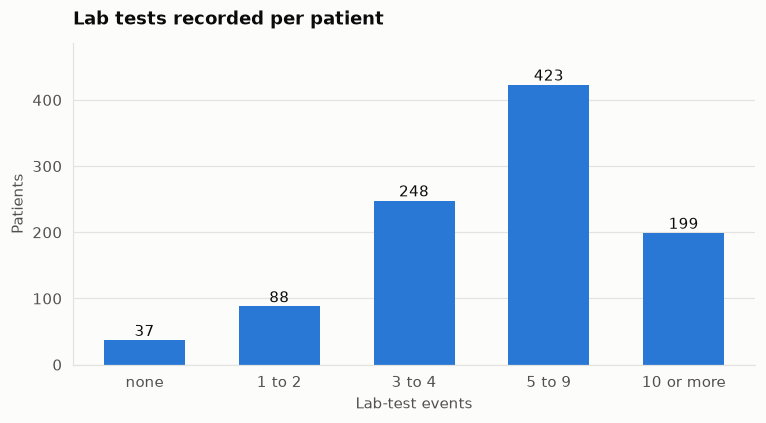

,value
Lab-test events,7507.0
Clinical-step events,6707.0
Median lab tests per patient,5.0


In [8]:
labs = lab_tests_per_patient(log)
edges = [0, 1, 3, 5, 10, np.inf]
labels = ['none', '1 to 2', '3 to 4', '5 to 9', '10 or more']
lab_groups = pd.cut(labs, bins=edges, labels=labels, right=False).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(lab_groups.index, lab_groups.values, color=BLUE, width=0.6)
ax.grid(axis='x', visible=False)
for i, v in enumerate(lab_groups.values):
    ax.text(i, v + lab_groups.max() * 0.015, f'{v}', ha='center', color=INK, fontsize=10)
ax.set_ylim(0, lab_groups.max() * 1.15)
ax.set_title('Lab tests recorded per patient')
ax.set_xlabel('Lab-test events')
ax.set_ylabel('Patients')
save_fig(fig, 'rework_lab_tests')
plt.show()
pd.Series({'Lab-test events': int(summary['lab_events_total']), 'Clinical-step events': len(steps), 'Median lab tests per patient': summary['lab_tests_median_per_patient']}, name='value').to_frame()

## Findings
- **Rework in this data is almost entirely one thing: repeated ward admission records.** 300 patients (30%) repeat a clinical step, and 294 of them repeat `Admission NC` (356 extra records). Only 5 patients repeat an ICU admission and 3 repeat ER triage.
- **True loops are rare.** 325 repeats are a step directly after itself, but only 38 patients (4%) go back to a step after a different step in between.
- **The repeats come soon after each other.** 62% of the gaps between repeated ward records are under a day, and the most common gap is 12 to 24 hours. For patients with several records, the first and last record are a median of 0.8 days apart. This looks like transfers or re-recording around admission rather than daily updates, but the data cannot confirm it. It is a question for the mentor.
- **More ward records go with longer stays.** The median stay is 4.7 days with one record, 6.1 days with two, and 14.4 days with three or more (43 patients). This describes the data and does not show a cause: complex patients may simply be moved or recorded more often.
- **Return visits are the main loop.** 278 patients (37.6% of the 739 discharged) return, a median of 46.5 days after discharge. 44 returns (16%) come within a week and 111 (40%) within 30 days, so 15% of all discharged patients return within 30 days.
- **Lab tests are routine monitoring.** There are 7,507 lab events, more than the 6,707 clinical events, with a median of 5 per patient. They are not counted as rework.
- **Next step:** add Conformance and Rework tabs to the dashboard, with the ward-record pattern and the 30-day return rate.
